# SolarLeads: Model Training, Evaluation and Scoring

**SolarLeads: An ML-Driven Platform for Prioritising Housing Societies for Solar Energy Adoption**

This notebook reproduces the full modelling pipeline behind SolarLeads, end to end:

1. **Data**: 15,000 Maharashtra housing societies with past solar pitch outcomes (Converted / Rejected / Pending).
2. **Exploration**: distributions, correlations and conversion rates.
3. **Models**:
   - a majority-class **baseline**,
   - the **production model**: class-balanced logistic regression (exactly what the SolarLeads API trains at start-up),
   - logistic regression **trained from scratch by mini-batch gradient descent**, to show loss per epoch,
   - a **neural network** (MLP), with train/validation loss per epoch,
   - **gradient boosting**, with train/validation loss per boosting iteration.
4. **Evaluation**: confusion matrices, ROC and precision–recall curves, calibration, cross-validation, learning curves and threshold tuning.
5. **Explainability**: coefficients, permutation importance and a per-society explanation.
6. **Scoring and business logic**: scoring the Pending societies, savings, expected value, capacity allocation for a 5 MW farm (ILP knapsack vs greedy), groups of societies to pitch together and a Monte Carlo simulation of each group's outcome.
7. **Live-stream replay**: how accuracy settles as held-out rows arrive one by one, as on the dashboard.

**Run on Google Colab:** `Runtime → Run all`. The dataset downloads automatically from the project's GitHub repository, and every library used ships with Colab. It runs in about two minutes.

## 1. Setup

In [1]:
import os
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss, confusion_matrix, f1_score,
                             log_loss, precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_val_score, learning_curve, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# One consistent visual style for every chart.
COLORS = {"navy": "#1b3a5f", "blue": "#2f74c0", "amber": "#e09a00", "green": "#16a34a", "red": "#c0223d", "grey": "#9aa0ac"}
plt.rcParams.update({
    "figure.figsize": (9, 4.8), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold", "axes.titlesize": 13, "font.size": 11,
})
print("Ready.")

Ready.


In [2]:
# Use the repository copy when running locally; otherwise download it from GitHub (e.g. on Colab).
LOCAL_PATH = "../data/raw/maharashtra_solar_societies_synthetic.csv"
GITHUB_URL = "https://raw.githubusercontent.com/Heet-P/SGP-II/main/data/raw/maharashtra_solar_societies_synthetic.csv"
df = pd.read_csv(LOCAL_PATH if os.path.exists(LOCAL_PATH) else GITHUB_URL)
print(f"{len(df):,} rows × {df.shape[1]} columns")
df.head()

15,000 rows × 18 columns


,society_id,society_name,city,district,pincode,num_flats,avg_monthly_consumption_kwh,current_provider,current_tariff_rs_per_unit,distance_to_solar_farm_km,building_age_years,estimated_solar_tariff_rs_per_unit,estimated_monthly_savings_rs,secretary_name,secretary_phone,secretary_email,pitch_priority_score,pitch_outcome
0,MH-SOC-000001,Shanti CHS,Thane,Thane,408964,383,47482,Adani Electricity,11.02,10.5,35,9.24,84518,Sunita Thorat,+91-9535368239,sunita.thorat756@examplemail.in,36.7,Rejected
1,MH-SOC-000002,Lotus Heights 6,Ahmednagar,Ahmednagar,401535,221,43141,Adani Electricity,10.15,45.4,3,8.06,90165,Prakash Sawant,+91-9016280135,prakash.sawant502@mailsociety.example,32.2,Rejected
2,MH-SOC-000003,Maple Heights 2,Latur,Latur,428418,321,44152,MSEDCL,11.27,40.8,36,9.30,86979,Sandeep Salunkhe,+91-9317545211,sandeep.salunkhe343@examplemail.in,32.7,Rejected
3,MH-SOC-000004,Vasant Vihar Park,Amravati,Amravati,430942,434,154924,BEST,10.08,38.2,25,8.25,283511,Snehal Mane,+91-9782580680,snehal.mane625@examplemail.in,76.7,Pending
4,MH-SOC-000005,Riverside Heights,Amravati,Amravati,435001,50,11368,Tata Power,10.61,34.9,6,8.47,24328,Nitin Deshmukh,+91-9930873378,nitin.deshmukh494@mailsociety.example,20.0,Rejected


## 2. Data overview

In [3]:
overview = pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum(), "unique": df.nunique()})
overview

,dtype,missing,unique
society_id,object,0,15000
society_name,object,0,2342
city,object,0,20
district,object,0,18
pincode,int64,0,12754
num_flats,int64,0,420
avg_monthly_consumption_kwh,int64,0,13959
current_provider,object,0,4
current_tariff_rs_per_unit,float64,0,440
distance_to_solar_farm_km,float64,0,1051


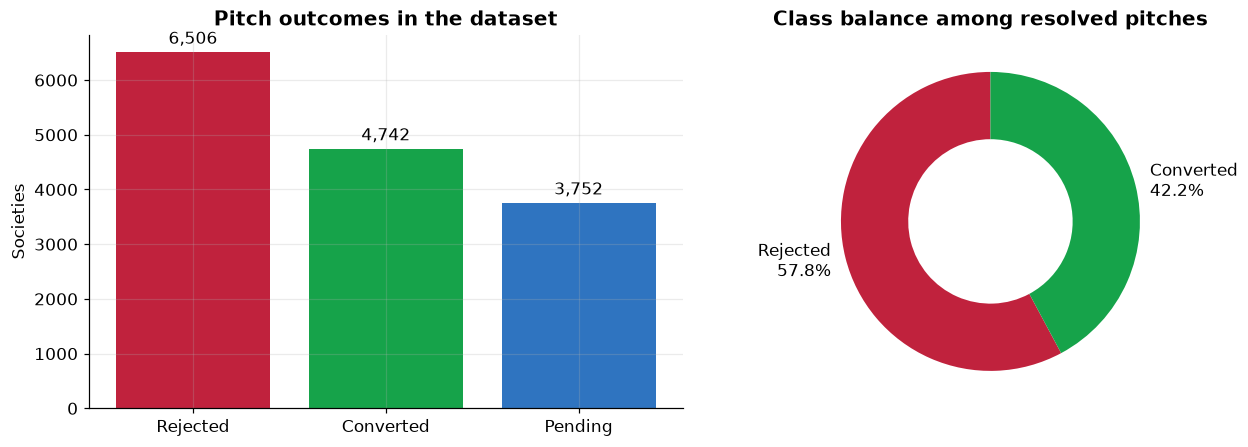

Resolved (labelled) rows: 11,248 · Pending (unlabelled, scored later): 3,752


In [4]:
counts = df["pitch_outcome"].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
bars = axes[0].bar(counts.index, counts.values, color=[COLORS["red"], COLORS["green"], COLORS["blue"]])
axes[0].bar_label(bars, labels=[f"{v:,}" for v in counts.values], padding=3)
axes[0].set_title("Pitch outcomes in the dataset")
axes[0].set_ylabel("Societies")

resolved = df[df["pitch_outcome"].isin(["Converted", "Rejected"])]
share = resolved["pitch_outcome"].value_counts(normalize=True)
axes[1].pie(share, labels=[f"{k}\n{v:.1%}" for k, v in share.items()], colors=[COLORS["red"], COLORS["green"]],
            startangle=90, wedgeprops={"width": 0.45})
axes[1].set_title("Class balance among resolved pitches")
plt.tight_layout()
plt.show()
print(f"Resolved (labelled) rows: {len(resolved):,} · Pending (unlabelled, scored later): {(df.pitch_outcome == 'Pending').sum():,}")

The **resolved** rows (Converted or Rejected) are used to train and test the model.
The **Pending** rows have no outcome yet; they are the new leads the model ranks.
The classes are mildly imbalanced (about 42% converted), so the production model uses class-balanced weights.

## 3. Exploratory data analysis

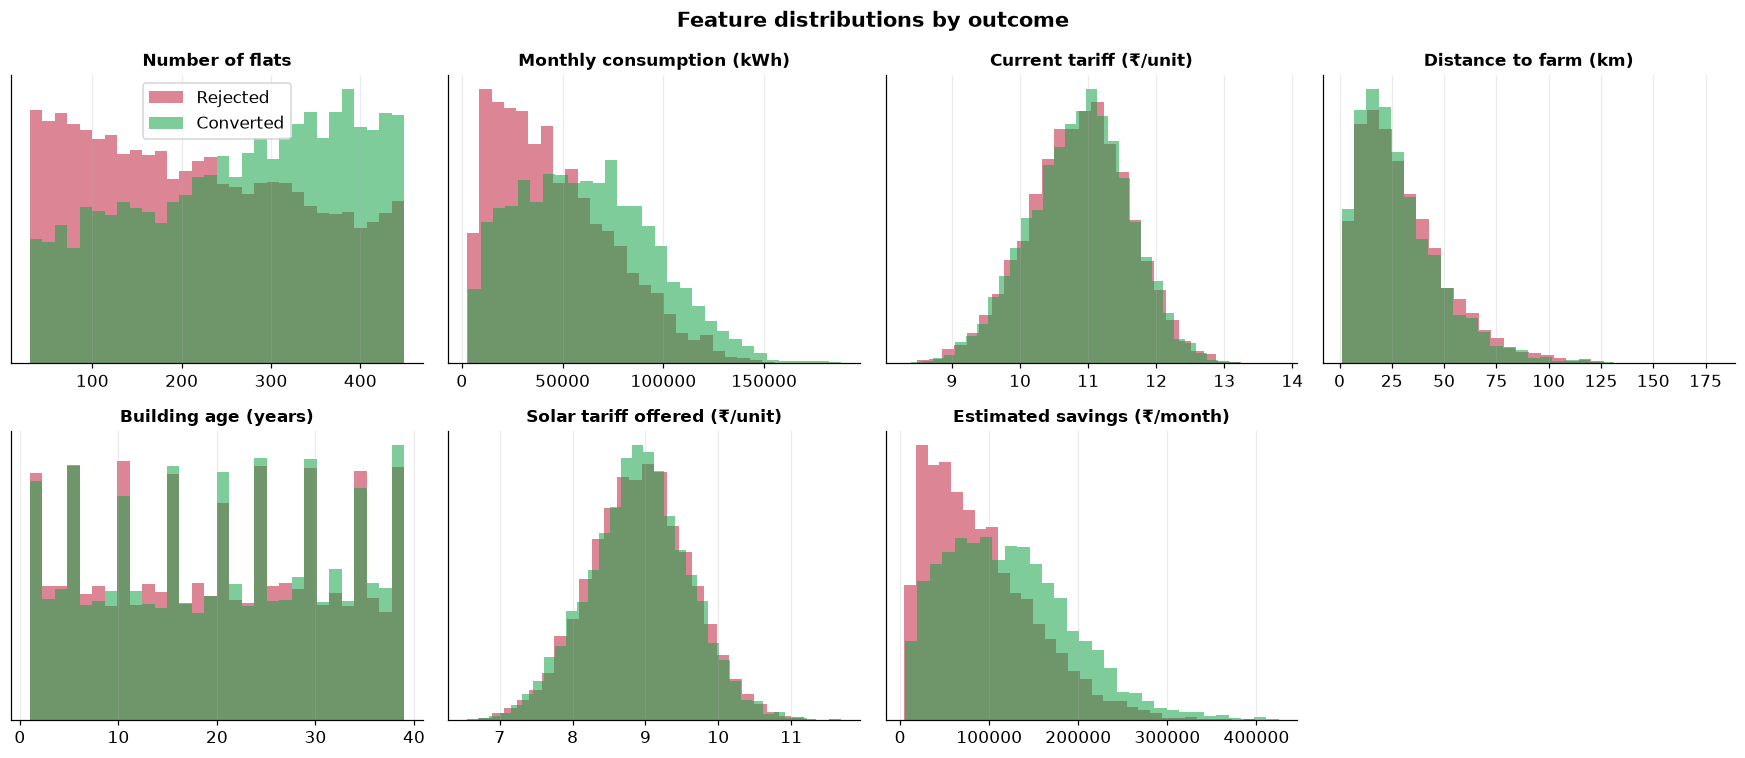

In [5]:
NUMERIC = ["num_flats", "avg_monthly_consumption_kwh", "current_tariff_rs_per_unit", "distance_to_solar_farm_km",
           "building_age_years", "estimated_solar_tariff_rs_per_unit", "estimated_monthly_savings_rs"]
CATEGORICAL = ["current_provider", "district"]
FEATURES = NUMERIC + CATEGORICAL
LABELS = {
    "num_flats": "Number of flats", "avg_monthly_consumption_kwh": "Monthly consumption (kWh)",
    "current_tariff_rs_per_unit": "Current tariff (₹/unit)", "distance_to_solar_farm_km": "Distance to farm (km)",
    "building_age_years": "Building age (years)", "estimated_solar_tariff_rs_per_unit": "Solar tariff offered (₹/unit)",
    "estimated_monthly_savings_rs": "Estimated savings (₹/month)", "current_provider": "Current provider", "district": "District",
}

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, NUMERIC):
    for outcome, color in [("Rejected", COLORS["red"]), ("Converted", COLORS["green"])]:
        ax.hist(resolved.loc[resolved.pitch_outcome == outcome, col], bins=30, alpha=0.55, color=color,
                label=outcome, density=True)
    ax.set_title(LABELS[col], fontsize=11)
    ax.set_yticks([])
axes.flat[0].legend()
axes.flat[-1].axis("off")
fig.suptitle("Feature distributions by outcome", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

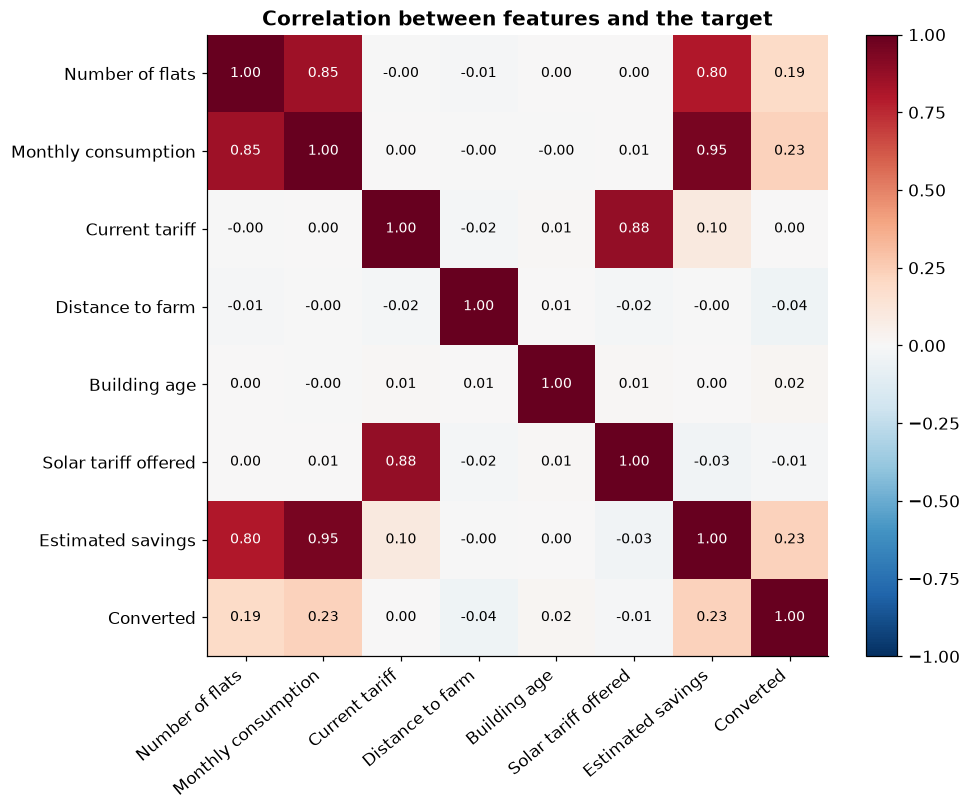

,correlation with converting
distance_to_solar_farm_km,-0.040181
estimated_solar_tariff_rs_per_unit,-0.008672
current_tariff_rs_per_unit,0.004009
building_age_years,0.020958
num_flats,0.194572
estimated_monthly_savings_rs,0.229869
avg_monthly_consumption_kwh,0.232094


In [6]:
corr = resolved.assign(converted=(resolved.pitch_outcome == "Converted").astype(int))[NUMERIC + ["converted"]].corr()
names = [LABELS.get(c, "Converted (target)").split(" (")[0] for c in corr.columns]
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(names)), names, rotation=40, ha="right")
ax.set_yticks(range(len(names)), names)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(corr.iloc[i, j]) > 0.5 else "black")
ax.grid(False)
fig.colorbar(im, fraction=0.046)
ax.set_title("Correlation between features and the target")
plt.tight_layout()
plt.show()
corr["converted"].drop("converted").sort_values().rename("correlation with converting").to_frame()

**Reading the correlations:** only flat count, monthly consumption and estimated savings correlate noticeably
with converting (about 0.2 each). Savings are derived from tariff × consumption, so those three move together.
Tariff, distance and building age carry very little signal on their own. This limits how accurate any model can be.

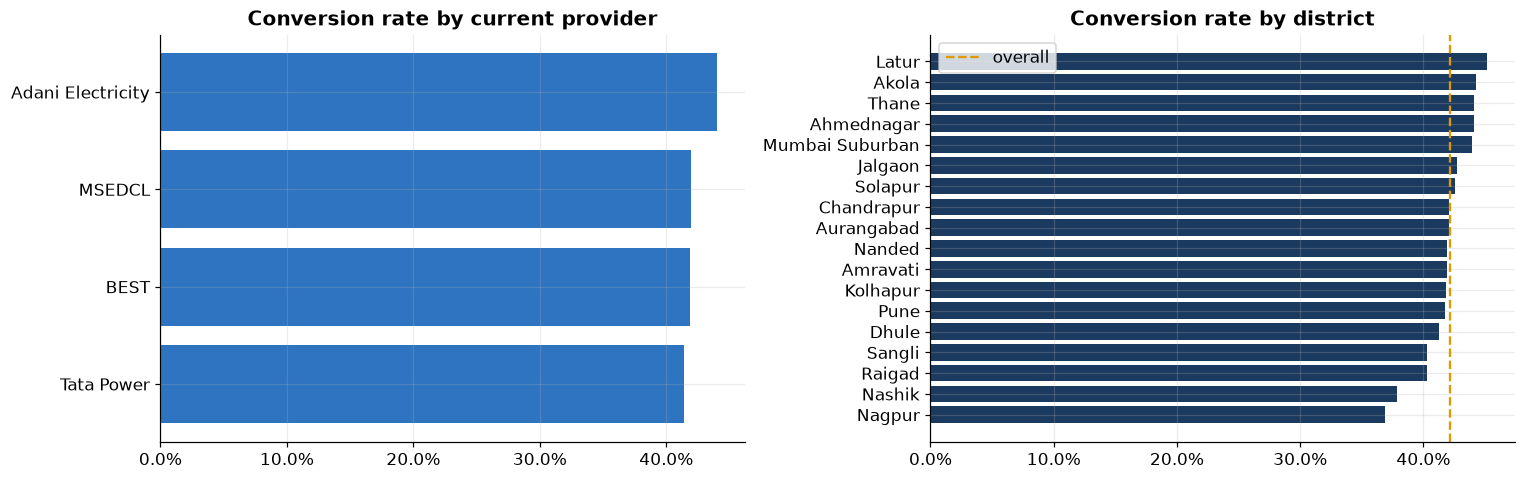

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
rate = lambda g: (g == "Converted").mean()
by_provider = resolved.groupby("current_provider")["pitch_outcome"].agg(rate).sort_values()
axes[0].barh(by_provider.index, by_provider.values, color=COLORS["blue"])
axes[0].xaxis.set_major_formatter(PercentFormatter(1))
axes[0].set_title("Conversion rate by current provider")

by_district = resolved.groupby("district")["pitch_outcome"].agg(rate).sort_values()
axes[1].barh(by_district.index, by_district.values, color=COLORS["navy"])
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
axes[1].axvline(rate(resolved["pitch_outcome"]), color=COLORS["amber"], ls="--", label="overall")
axes[1].legend()
axes[1].set_title("Conversion rate by district")
plt.tight_layout()
plt.show()

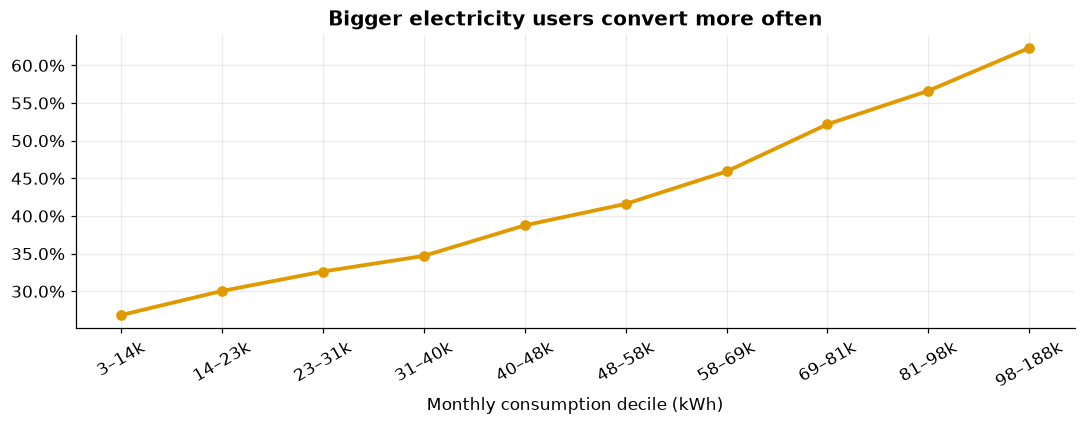

In [8]:
bins = pd.qcut(resolved["avg_monthly_consumption_kwh"], 10)
by_bin = resolved.groupby(bins, observed=True)["pitch_outcome"].agg(rate)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(range(10), by_bin.values, marker="o", color=COLORS["amber"], lw=2.5)
ax.set_xticks(range(10), [f"{iv.left / 1000:.0f}–{iv.right / 1000:.0f}k" for iv in by_bin.index], rotation=30)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("Monthly consumption decile (kWh)")
ax.set_title("Bigger electricity users convert more often")
plt.tight_layout()
plt.show()

## 4. Train / validation / test split and preprocessing

In [9]:
y_all = (resolved["pitch_outcome"] == "Converted").astype(int)
# Same 80/20 stratified split as the production API, so test results match what the dashboard reports.
X_train_full, X_test, y_train_full, y_test = train_test_split(
    resolved[FEATURES], y_all, test_size=0.2, stratify=y_all, random_state=RANDOM_STATE)
# A validation slice of the training data, used only to draw loss curves for the epoch-based models.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.15, stratify=y_train_full, random_state=RANDOM_STATE)

def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), NUMERIC),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), CATEGORICAL),
    ])

pre = make_preprocessor().fit(X_train)
def to_dense(X):
    m = pre.transform(X)
    return m.toarray() if hasattr(m, "toarray") else m
Xtr, Xva, Xte = to_dense(X_train), to_dense(X_val), to_dense(X_test)

split = pd.DataFrame({
    "rows": [len(X_train), len(X_val), len(X_test)],
    "converted share": [y_train.mean(), y_val.mean(), y_test.mean()],
}, index=["train", "validation", "test"])
print(f"{Xtr.shape[1]} model inputs after one-hot encoding")
split.style.format({"rows": "{:,}", "converted share": "{:.1%}"})

27 model inputs after one-hot encoding


,rows,converted share
train,"7,648",42.2%
validation,"1,350",42.1%
test,"2,250",42.2%


## 5. Baseline

In [10]:
baseline_acc = 1 - y_test.mean()
print(f"Always predicting 'Rejected' scores {baseline_acc:.1%} accuracy on the test set.")
print("Any useful model has to beat this, and should rank societies better than chance (ROC AUC > 0.5).")

Always predicting 'Rejected' scores 57.8% accuracy on the test set.
Any useful model has to beat this, and should rank societies better than chance (ROC AUC > 0.5).


## 6. Production model: class-balanced logistic regression

This is exactly the model the SolarLeads API trains when it starts (`backend/app/model.py`):
standardised numeric features plus one-hot provider and district, with balanced class weights.
It is trained on the full 80% training split.

In [11]:
production = Pipeline([
    ("preprocess", make_preprocessor()),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)),
])
start = time.perf_counter()
production.fit(X_train_full, y_train_full)
print(f"Trained on {len(X_train_full):,} rows in {(time.perf_counter() - start) * 1000:.0f} ms")

def evaluate(name, y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {"model": name, "accuracy": accuracy_score(y_true, pred), "precision": precision_score(y_true, pred),
            "recall": recall_score(y_true, pred), "f1": f1_score(y_true, pred), "roc_auc": roc_auc_score(y_true, proba),
            "avg_precision": average_precision_score(y_true, proba), "log_loss": log_loss(y_true, proba),
            "brier": brier_score_loss(y_true, proba)}

p_prod = production.predict_proba(X_test)[:, 1]
results = [evaluate("Baseline (always Rejected)", y_test, np.full(len(y_test), y_train_full.mean())),
           evaluate("Logistic regression (production)", y_test, p_prod)]
pd.DataFrame(results).set_index("model").style.format("{:.3f}")

Trained on 8,998 rows in 35 ms


,accuracy,precision,recall,f1,roc_auc,avg_precision,log_loss,brier
model,,,,,,,,
Baseline (always Rejected),0.578,0.000,0.000,0.000,0.500,0.422,0.681,0.244
Logistic regression (production),0.599,0.523,0.542,0.532,0.613,0.528,0.674,0.240


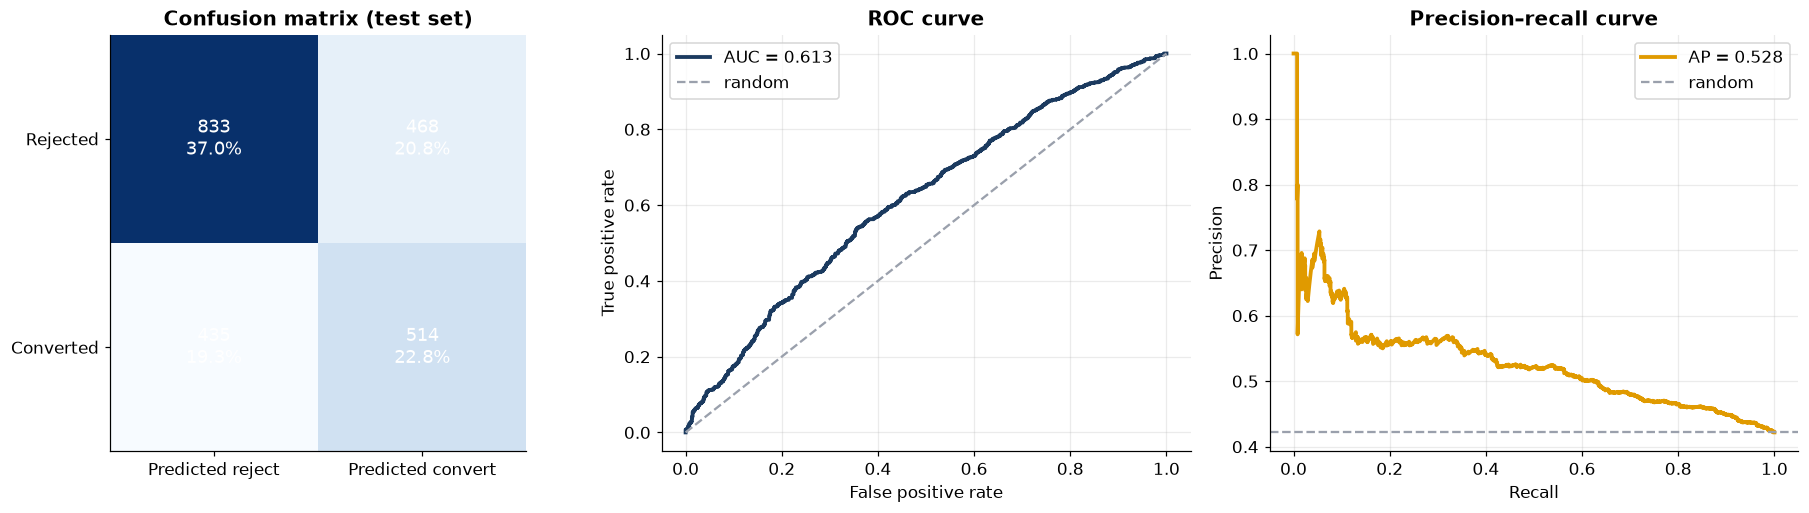

In [12]:
def plot_confusion(ax, y_true, proba, title, threshold=0.5):
    cm = confusion_matrix(y_true, (proba >= threshold).astype(int))
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n{cm[i, j] / cm.sum():.1%}", ha="center", va="center", fontsize=12,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["Predicted reject", "Predicted convert"])
    ax.set_yticks([0, 1], ["Rejected", "Converted"])
    ax.grid(False)
    ax.set_title(title)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
plot_confusion(axes[0], y_test, p_prod, "Confusion matrix (test set)")

fpr, tpr, _ = roc_curve(y_test, p_prod)
axes[1].plot(fpr, tpr, color=COLORS["navy"], lw=2.5, label=f"AUC = {roc_auc_score(y_test, p_prod):.3f}")
axes[1].plot([0, 1], [0, 1], ls="--", color=COLORS["grey"], label="random")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC curve"); axes[1].legend()

prec, rec, _ = precision_recall_curve(y_test, p_prod)
axes[2].plot(rec, prec, color=COLORS["amber"], lw=2.5, label=f"AP = {average_precision_score(y_test, p_prod):.3f}")
axes[2].axhline(y_test.mean(), ls="--", color=COLORS["grey"], label="random")
axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision")
axes[2].set_title("Precision–recall curve"); axes[2].legend()
plt.tight_layout()
plt.show()

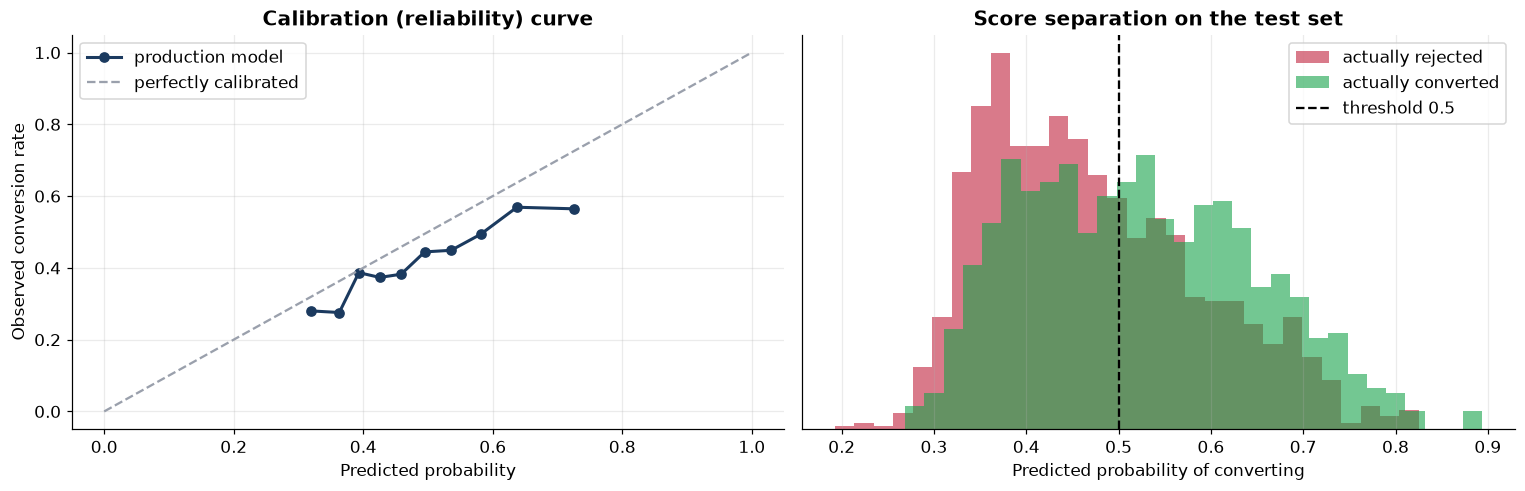

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
frac_pos, mean_pred = calibration_curve(y_test, p_prod, n_bins=10, strategy="quantile")
axes[0].plot(mean_pred, frac_pos, marker="o", color=COLORS["navy"], lw=2, label="production model")
axes[0].plot([0, 1], [0, 1], ls="--", color=COLORS["grey"], label="perfectly calibrated")
axes[0].set_xlabel("Predicted probability"); axes[0].set_ylabel("Observed conversion rate")
axes[0].set_title("Calibration (reliability) curve"); axes[0].legend()

axes[1].hist(p_prod[y_test == 0], bins=30, alpha=0.6, color=COLORS["red"], label="actually rejected", density=True)
axes[1].hist(p_prod[y_test == 1], bins=30, alpha=0.6, color=COLORS["green"], label="actually converted", density=True)
axes[1].axvline(0.5, ls="--", color="black", label="threshold 0.5")
axes[1].set_xlabel("Predicted probability of converting"); axes[1].set_yticks([])
axes[1].set_title("Score separation on the test set"); axes[1].legend()
plt.tight_layout()
plt.show()

## 7. Logistic regression from scratch: loss per epoch

Scikit-learn's solver does not expose epochs, so here the same model (weighted logistic loss with L2
regularisation) is trained by **mini-batch gradient descent in NumPy**. Tracking training and validation
loss each epoch shows the optimisation converging, and the result should match the production model.

In [14]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -30, 30)))

def balanced_weights(y):
    # Balanced class weights, as in the production model: each class contributes equally to the loss.
    return np.where(y == 1, len(y) / (2 * (y == 1).sum()), len(y) / (2 * (y == 0).sum()))

def train_logreg_gd(X, y, X_val, y_val, epochs=60, lr=0.05, batch=256, l2=1e-3, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    n, d = X.shape
    w, b = np.zeros(d), 0.0
    sw, sw_val = balanced_weights(y), balanced_weights(y_val)
    history = {"epoch": [], "train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_auc": []}

    def record(epoch):
        p_tr, p_va = sigmoid(X @ w + b), sigmoid(X_val @ w + b)
        history["epoch"].append(epoch)
        # The class-weighted log-loss: the objective gradient descent is actually minimising.
        history["train_loss"].append(log_loss(y, p_tr, sample_weight=sw))
        history["val_loss"].append(log_loss(y_val, p_va, sample_weight=sw_val))
        history["train_acc"].append(accuracy_score(y, p_tr >= 0.5))
        history["val_acc"].append(accuracy_score(y_val, p_va >= 0.5))
        history["val_auc"].append(roc_auc_score(y_val, p_va) if epoch else 0.5)

    record(0)  # untrained: every prediction is 0.5, loss = ln 2 ≈ 0.693
    for epoch in range(1, epochs + 1):
        order = rng.permutation(n)
        for start in range(0, n, batch):
            idx = order[start:start + batch]
            p = sigmoid(X[idx] @ w + b)
            err = (p - y[idx]) * sw[idx]
            w -= lr * (X[idx].T @ err / len(idx) + l2 * w)
            b -= lr * err.mean()
        record(epoch)
    return w, b, pd.DataFrame(history)

w_gd, b_gd, hist_gd = train_logreg_gd(Xtr, y_train.to_numpy(), Xva, y_val.to_numpy())
p_gd = sigmoid(Xte @ w_gd + b_gd)
results.append(evaluate("Logistic regression (gradient descent)", y_test, p_gd))
hist_gd.tail()

,epoch,train_loss,val_loss,train_acc,val_acc,val_auc
56,56,0.659229,0.665877,0.612448,0.604444,0.632144
57,57,0.659235,0.665837,0.611794,0.602963,0.632144
58,58,0.659210,0.665872,0.612840,0.604444,0.632336
59,59,0.659207,0.665954,0.612186,0.605926,0.632219
60,60,0.659202,0.665984,0.612709,0.605185,0.632153


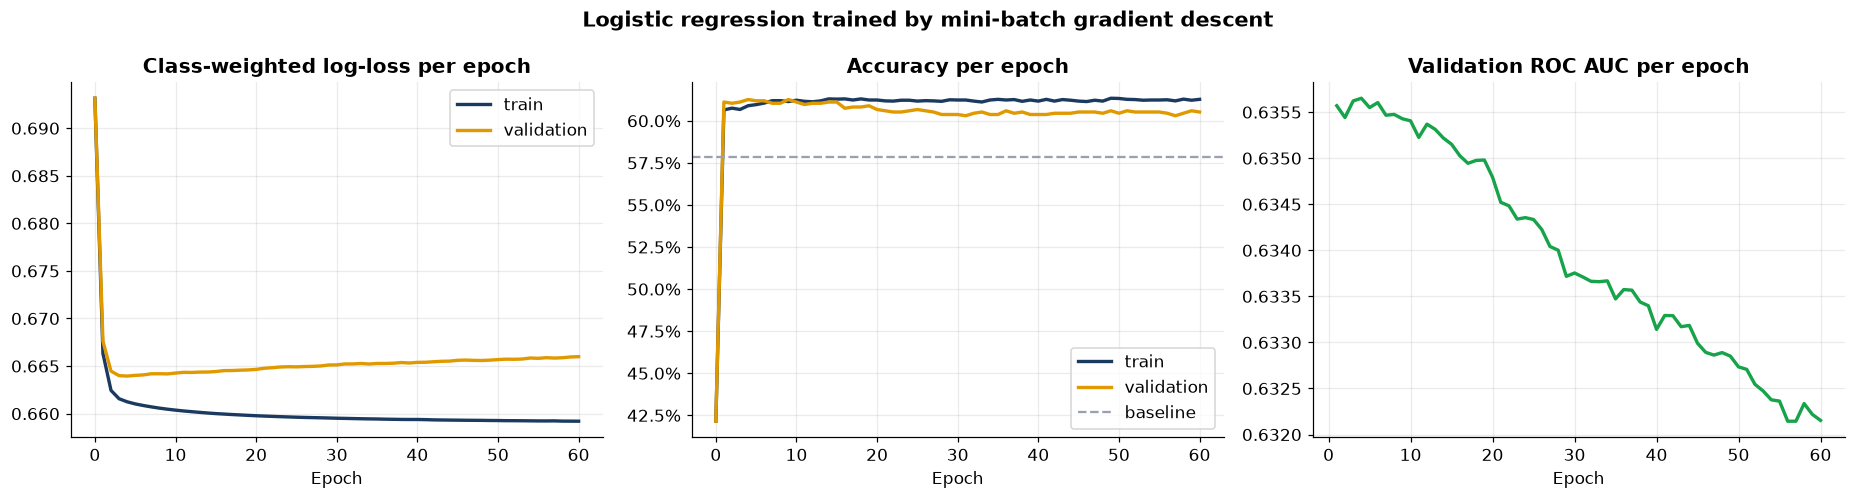

Test AUC: gradient descent 0.612 vs production solver 0.613


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
axes[0].plot(hist_gd.epoch, hist_gd.train_loss, color=COLORS["navy"], lw=2.2, label="train")
axes[0].plot(hist_gd.epoch, hist_gd.val_loss, color=COLORS["amber"], lw=2.2, label="validation")
axes[0].set_title("Class-weighted log-loss per epoch"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(hist_gd.epoch, hist_gd.train_acc, color=COLORS["navy"], lw=2.2, label="train")
axes[1].plot(hist_gd.epoch, hist_gd.val_acc, color=COLORS["amber"], lw=2.2, label="validation")
axes[1].axhline(1 - y_val.mean(), ls="--", color=COLORS["grey"], label="baseline")
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].set_title("Accuracy per epoch"); axes[1].set_xlabel("Epoch"); axes[1].legend()
axes[2].plot(hist_gd.epoch[1:], hist_gd.val_auc[1:], color=COLORS["green"], lw=2.2)
axes[2].set_title("Validation ROC AUC per epoch"); axes[2].set_xlabel("Epoch")
fig.suptitle("Logistic regression trained by mini-batch gradient descent", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()
print(f"Test AUC: gradient descent {roc_auc_score(y_test, p_gd):.3f} vs production solver {roc_auc_score(y_test, p_prod):.3f}")

**Reading the curves:** loss falls from ln 2 ≈ 0.693 (an untrained model guessing 50%) and converges within a few
epochs, matching the production solver. The small later rise in validation loss (about 0.002) is mild
overfitting; stopping around epoch 5 would be marginally better, but the difference is negligible.

## 8. Neural network (MLP): loss per epoch

A small two-layer neural network (32 → 16 units, ReLU) trained one epoch at a time with `partial_fit`,
recording training and validation loss after every epoch. If validation loss rises while training loss
keeps falling, the network is overfitting; the best epoch is marked.

Best validation loss 0.6582 at epoch 5


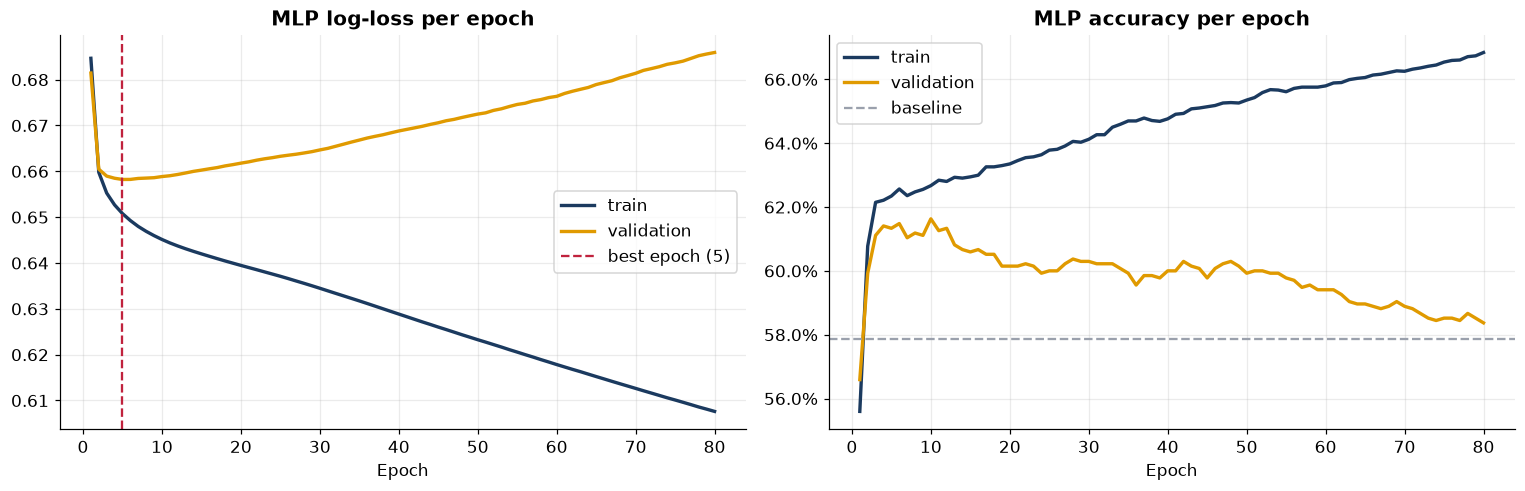

In [16]:
mlp = MLPClassifier(hidden_layer_sizes=(32, 16), alpha=1e-3, batch_size=256, learning_rate_init=1e-3,
                    random_state=RANDOM_STATE)
hist_mlp = {"epoch": [], "train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best = (np.inf, None)
for epoch in range(1, 81):
    mlp.partial_fit(Xtr, y_train, classes=[0, 1])
    p_tr, p_va = mlp.predict_proba(Xtr)[:, 1], mlp.predict_proba(Xva)[:, 1]
    hist_mlp["epoch"].append(epoch)
    hist_mlp["train_loss"].append(log_loss(y_train, p_tr))
    hist_mlp["val_loss"].append(log_loss(y_val, p_va))
    hist_mlp["train_acc"].append(accuracy_score(y_train, p_tr >= 0.5))
    hist_mlp["val_acc"].append(accuracy_score(y_val, p_va >= 0.5))
    if hist_mlp["val_loss"][-1] < best[0]:
        best = (hist_mlp["val_loss"][-1], epoch)
hist_mlp = pd.DataFrame(hist_mlp)

# Retrain to the best epoch so the test score reflects early stopping.
mlp_best = MLPClassifier(hidden_layer_sizes=(32, 16), alpha=1e-3, batch_size=256, learning_rate_init=1e-3,
                         random_state=RANDOM_STATE)
for _ in range(best[1]):
    mlp_best.partial_fit(Xtr, y_train, classes=[0, 1])
p_mlp = mlp_best.predict_proba(Xte)[:, 1]
results.append(evaluate("Neural network (MLP)", y_test, p_mlp))
print(f"Best validation loss {best[0]:.4f} at epoch {best[1]}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
axes[0].plot(hist_mlp.epoch, hist_mlp.train_loss, color=COLORS["navy"], lw=2.2, label="train")
axes[0].plot(hist_mlp.epoch, hist_mlp.val_loss, color=COLORS["amber"], lw=2.2, label="validation")
axes[0].axvline(best[1], ls="--", color=COLORS["red"], label=f"best epoch ({best[1]})")
axes[0].set_title("MLP log-loss per epoch"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(hist_mlp.epoch, hist_mlp.train_acc, color=COLORS["navy"], lw=2.2, label="train")
axes[1].plot(hist_mlp.epoch, hist_mlp.val_acc, color=COLORS["amber"], lw=2.2, label="validation")
axes[1].axhline(1 - y_val.mean(), ls="--", color=COLORS["grey"], label="baseline")
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].set_title("MLP accuracy per epoch"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout()
plt.show()

## 9. Gradient boosting: loss per boosting iteration

Histogram gradient boosting adds one shallow tree per iteration. With early stopping it keeps its own
validation slice and stops once validation loss stops improving.

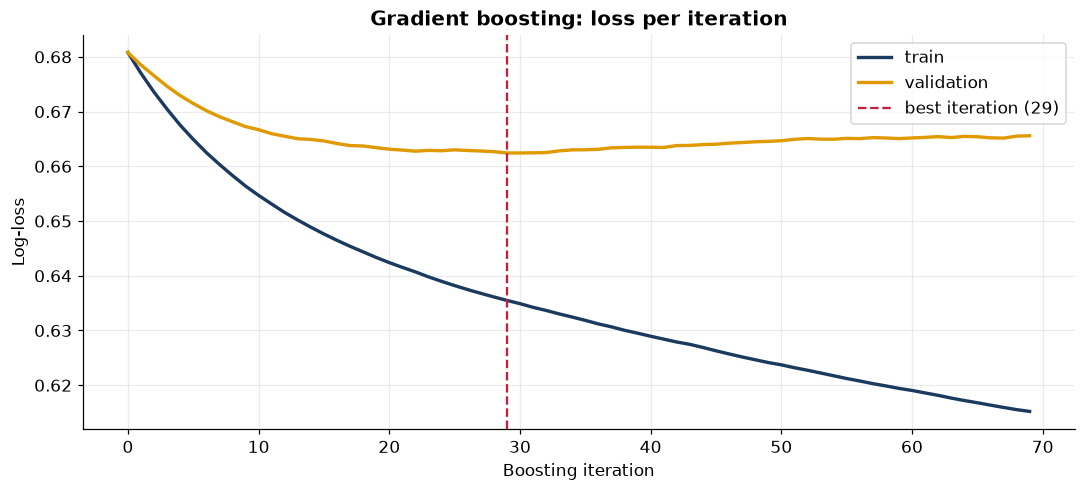

Stopped after 69 iterations.


In [17]:
hgb = HistGradientBoostingClassifier(max_iter=400, learning_rate=0.05, max_leaf_nodes=15, early_stopping=True,
                                     scoring="loss", validation_fraction=0.15, n_iter_no_change=40,
                                     random_state=RANDOM_STATE)
hgb.fit(np.vstack([Xtr, Xva]), np.concatenate([y_train, y_val]))
p_hgb = hgb.predict_proba(Xte)[:, 1]
results.append(evaluate("Gradient boosting", y_test, p_hgb))

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot(-hgb.train_score_, color=COLORS["navy"], lw=2.2, label="train")
ax.plot(-hgb.validation_score_, color=COLORS["amber"], lw=2.2, label="validation")
best_it = int(np.argmax(hgb.validation_score_))
ax.axvline(best_it, ls="--", color=COLORS["red"], label=f"best iteration ({best_it})")
ax.set_xlabel("Boosting iteration"); ax.set_ylabel("Log-loss")
ax.set_title("Gradient boosting: loss per iteration"); ax.legend()
plt.tight_layout()
plt.show()
print(f"Stopped after {hgb.n_iter_} iterations.")

## 10. Model comparison (test set)

In [18]:
comparison = pd.DataFrame(results).set_index("model")
display_cols = ["accuracy", "precision", "recall", "f1", "roc_auc", "avg_precision", "log_loss", "brier"]
comparison[display_cols].style.format("{:.3f}") \
    .highlight_max(subset=["accuracy", "precision", "recall", "f1", "roc_auc", "avg_precision"], color="#d9f2e0") \
    .highlight_min(subset=["log_loss", "brier"], color="#d9f2e0")

,accuracy,precision,recall,f1,roc_auc,avg_precision,log_loss,brier
model,,,,,,,,
Baseline (always Rejected),0.578,0.000,0.000,0.000,0.500,0.422,0.681,0.244
Logistic regression (production),0.599,0.523,0.542,0.532,0.613,0.528,0.674,0.240
Logistic regression (gradient descent),0.596,0.520,0.536,0.528,0.612,0.525,0.675,0.241
Neural network (MLP),0.607,0.546,0.403,0.464,0.607,0.527,0.666,0.236
Gradient boosting,0.601,0.540,0.360,0.432,0.605,0.522,0.666,0.237


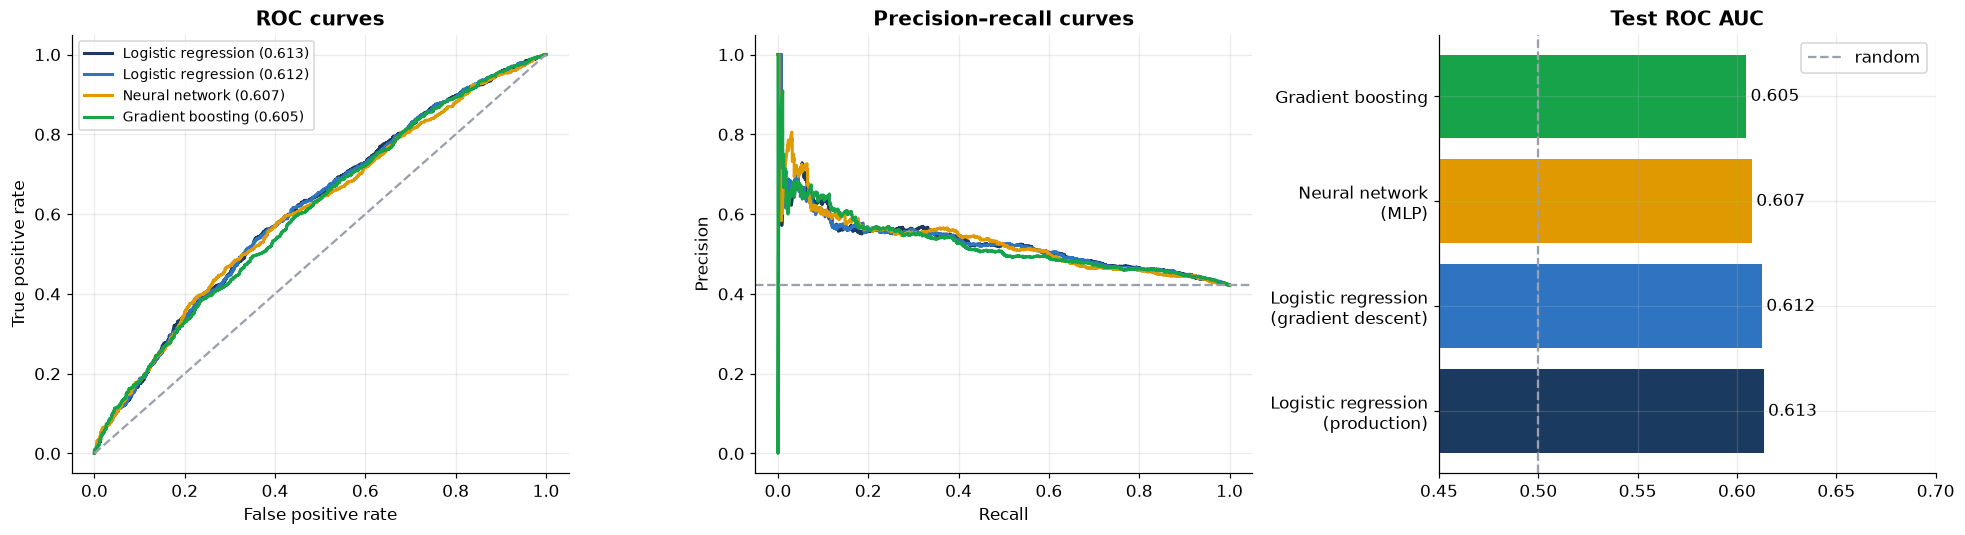

In [19]:
curves = [("Logistic regression (production)", p_prod, COLORS["navy"]),
          ("Logistic regression (gradient descent)", p_gd, COLORS["blue"]),
          ("Neural network (MLP)", p_mlp, COLORS["amber"]),
          ("Gradient boosting", p_hgb, COLORS["green"])]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for name, p, color in curves:
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=color, lw=2, label=f"{name.split(' (')[0]} ({roc_auc_score(y_test, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, color=color, lw=2, label=name.split(" (")[0])
axes[0].plot([0, 1], [0, 1], ls="--", color=COLORS["grey"])
axes[0].set_title("ROC curves"); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].legend(fontsize=9)
axes[1].axhline(y_test.mean(), ls="--", color=COLORS["grey"])
axes[1].set_title("Precision–recall curves"); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
auc = comparison["roc_auc"].drop("Baseline (always Rejected)")
bars = axes[2].barh([n.replace(" (", "\n(") for n in auc.index], auc.values,
                    color=[COLORS["navy"], COLORS["blue"], COLORS["amber"], COLORS["green"]])
axes[2].bar_label(bars, fmt="%.3f", padding=3)
axes[2].axvline(0.5, ls="--", color=COLORS["grey"], label="random")
axes[2].set_xlim(0.45, max(auc.max() + 0.05, 0.7)); axes[2].set_title("Test ROC AUC"); axes[2].legend()
plt.tight_layout()
plt.show()

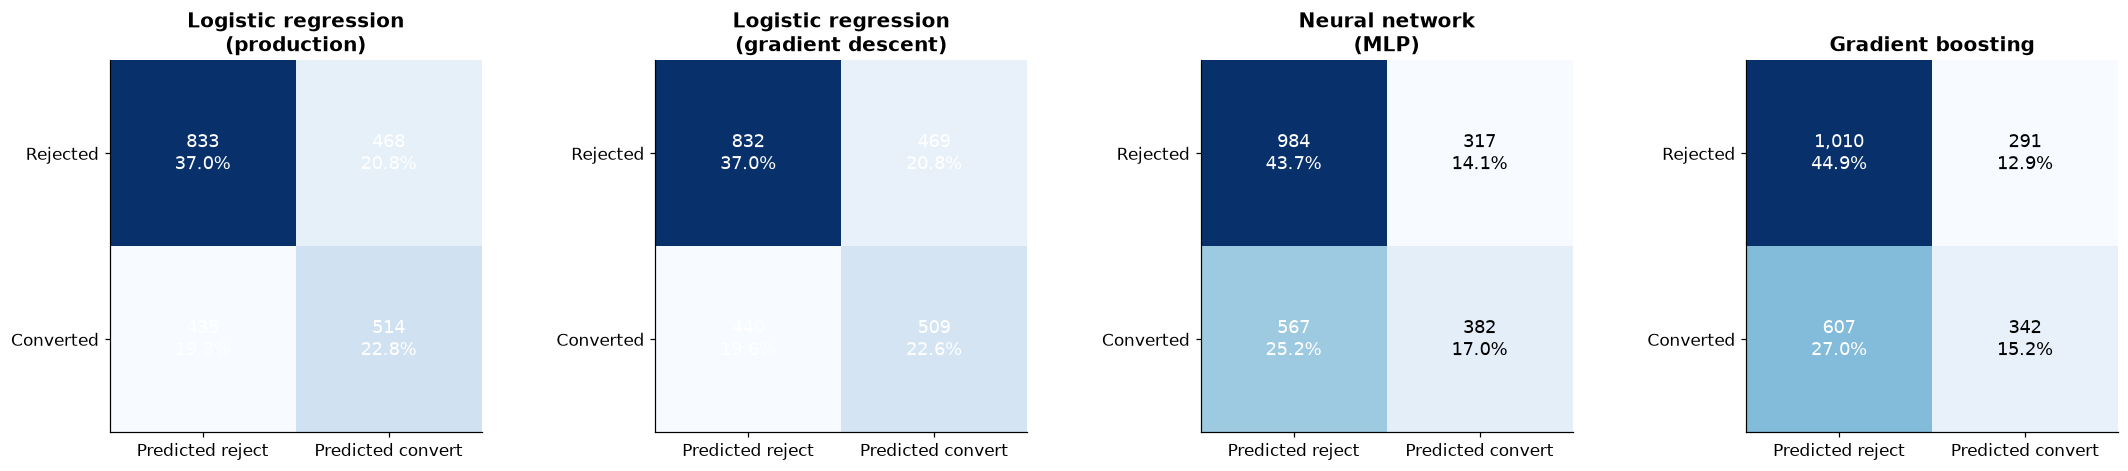

In [20]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.4))
for ax, (name, p, _) in zip(axes, curves):
    plot_confusion(ax, y_test, p, name.replace(" (", "\n("))
plt.tight_layout()
plt.show()

## 11. Cross-validation (5-fold, stratified)

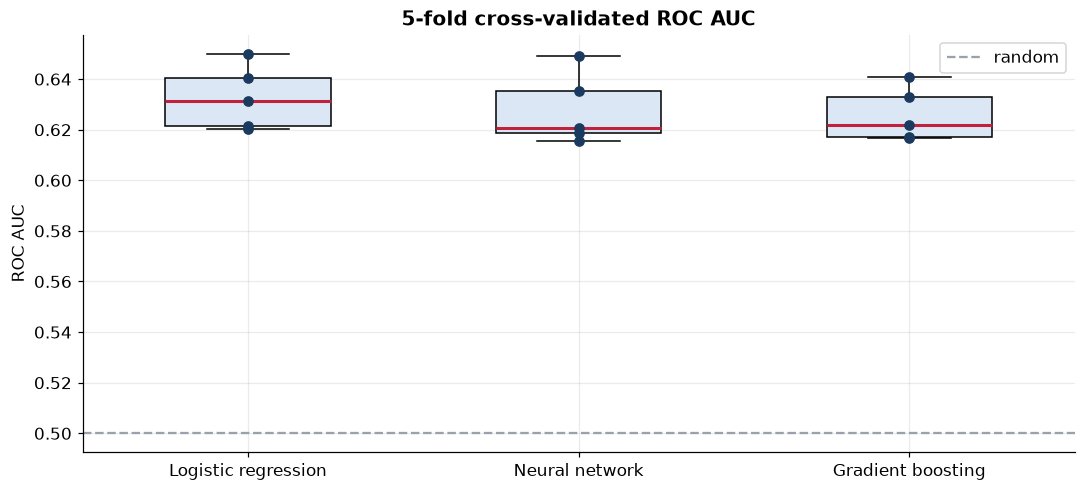

,mean AUC,std
Logistic regression,0.633,0.011
Neural network,0.628,0.013
Gradient boosting,0.626,0.009


In [21]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
X_cv, y_cv = resolved[FEATURES], y_all
cv_models = {
    "Logistic regression": production,
    "Neural network": Pipeline([("preprocess", make_preprocessor()),
                                ("clf", MLPClassifier(hidden_layer_sizes=(32, 16), alpha=1e-3, batch_size=256,
                                                      max_iter=max(best[1], 10), random_state=RANDOM_STATE))]),
    "Gradient boosting": Pipeline([("preprocess", make_preprocessor()),
                                   ("clf", HistGradientBoostingClassifier(max_iter=max(hgb.n_iter_, 20), learning_rate=0.05,
                                                                          max_leaf_nodes=15, random_state=RANDOM_STATE))]),
}
cv_scores = {name: cross_val_score(m, X_cv, y_cv, cv=cv, scoring="roc_auc") for name, m in cv_models.items()}

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.boxplot(list(cv_scores.values()), tick_labels=list(cv_scores.keys()), widths=0.5, patch_artist=True,
           boxprops={"facecolor": "#dbe7f5"}, medianprops={"color": COLORS["red"], "lw": 2})
for i, s in enumerate(cv_scores.values(), start=1):
    ax.scatter(np.full(len(s), i), s, color=COLORS["navy"], zorder=3)
ax.axhline(0.5, ls="--", color=COLORS["grey"], label="random")
ax.set_ylabel("ROC AUC"); ax.set_title("5-fold cross-validated ROC AUC"); ax.legend()
plt.tight_layout()
plt.show()
pd.DataFrame({k: {"mean AUC": v.mean(), "std": v.std()} for k, v in cv_scores.items()}).T.style.format("{:.3f}")

## 12. Learning curve: does more data help?

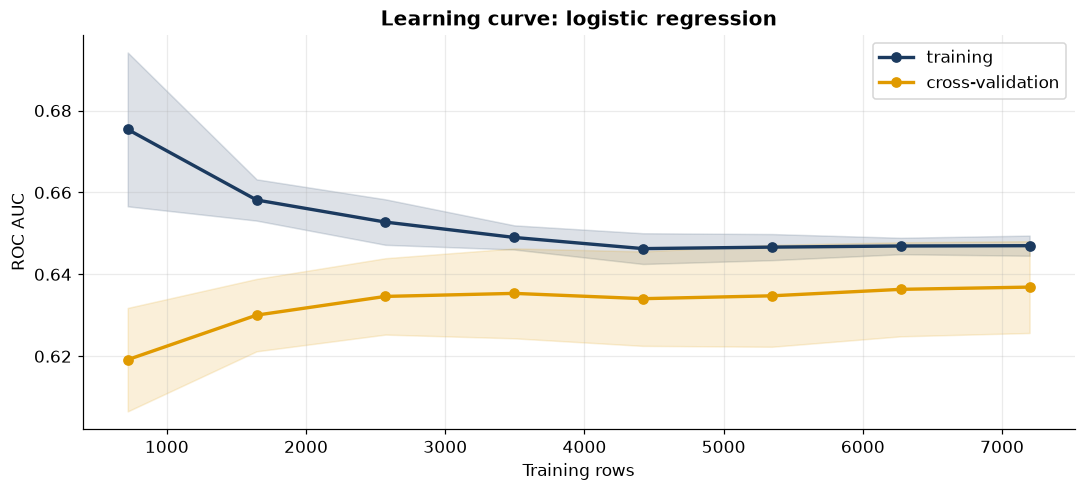

In [22]:
sizes, train_sc, val_sc = learning_curve(production, X_train_full, y_train_full, cv=cv, scoring="roc_auc",
                                         train_sizes=np.linspace(0.1, 1.0, 8), shuffle=True,
                                         random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(10, 4.6))
for scores, color, label in [(train_sc, COLORS["navy"], "training"), (val_sc, COLORS["amber"], "cross-validation")]:
    ax.plot(sizes, scores.mean(1), marker="o", color=color, lw=2.2, label=label)
    ax.fill_between(sizes, scores.mean(1) - scores.std(1), scores.mean(1) + scores.std(1), color=color, alpha=0.15)
ax.set_xlabel("Training rows"); ax.set_ylabel("ROC AUC")
ax.set_title("Learning curve: logistic regression"); ax.legend()
plt.tight_layout()
plt.show()

The training and validation curves meet early and stay close, so the model is not overfitting and more
rows of the *same* data would add little. Better accuracy needs more informative features
(for example real consumption history or committee decision data) rather than a bigger model.

## 13. Choosing the decision threshold

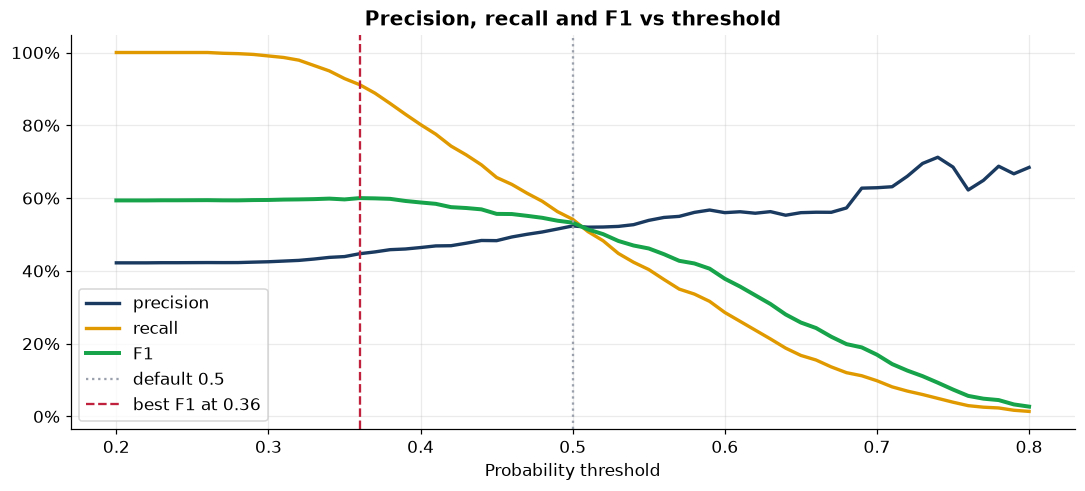

At 0.50: precision 52.3%, recall 54.2%
At 0.36: precision 44.7%, recall 91.1%


In [23]:
thresholds = np.linspace(0.2, 0.8, 61)
pr = [precision_score(y_test, p_prod >= t, zero_division=0) for t in thresholds]
rc = [recall_score(y_test, p_prod >= t) for t in thresholds]
f1 = [f1_score(y_test, p_prod >= t) for t in thresholds]
best_t = thresholds[int(np.argmax(f1))]

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot(thresholds, pr, color=COLORS["navy"], lw=2.2, label="precision")
ax.plot(thresholds, rc, color=COLORS["amber"], lw=2.2, label="recall")
ax.plot(thresholds, f1, color=COLORS["green"], lw=2.6, label="F1")
ax.axvline(0.5, ls=":", color=COLORS["grey"], label="default 0.5")
ax.axvline(best_t, ls="--", color=COLORS["red"], label=f"best F1 at {best_t:.2f}")
ax.set_xlabel("Probability threshold"); ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_title("Precision, recall and F1 vs threshold"); ax.legend()
plt.tight_layout()
plt.show()
print(f"At 0.50: precision {precision_score(y_test, p_prod >= 0.5):.1%}, recall {recall_score(y_test, p_prod >= 0.5):.1%}")
print(f"At {best_t:.2f}: precision {precision_score(y_test, p_prod >= best_t):.1%}, recall {recall_score(y_test, p_prod >= best_t):.1%}")

For lead prioritisation the threshold matters less than the **ranking**: SolarLeads sorts societies by
expected value (chance × savings) and pitches from the top, so ROC AUC is the key metric.

## 14. Explainability

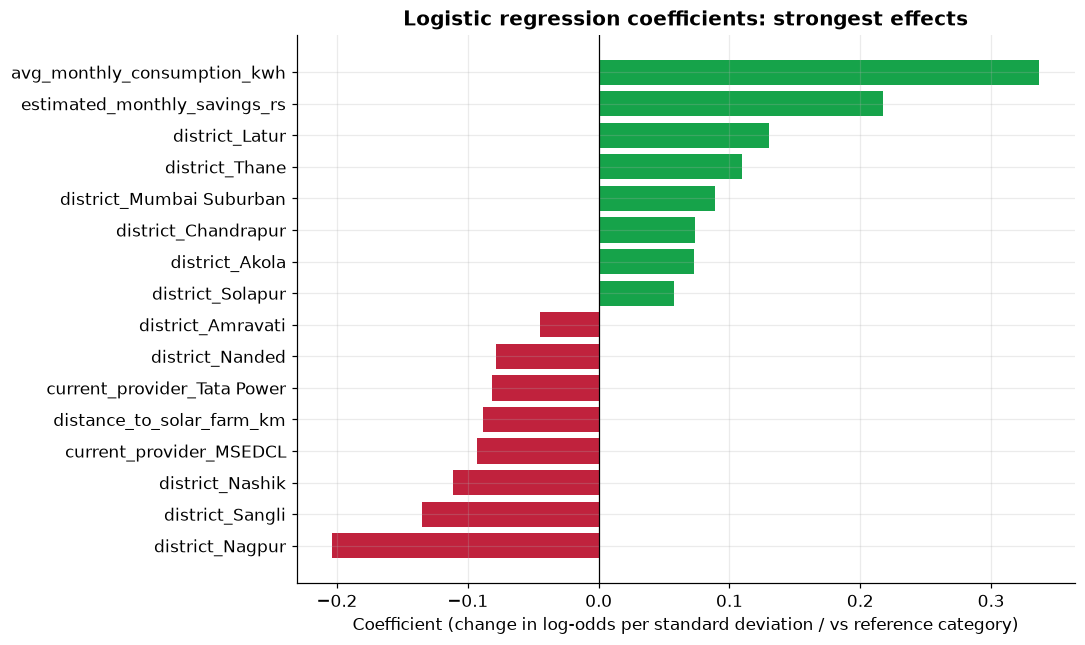

In [24]:
clf = production.named_steps["clf"]
names = production.named_steps["preprocess"].get_feature_names_out()
coef = pd.Series(clf.coef_[0], index=[n.split("__", 1)[1] for n in names]).sort_values()
top = pd.concat([coef.head(8), coef.tail(8)])
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top.index, top.values, color=[COLORS["green"] if v > 0 else COLORS["red"] for v in top.values])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Coefficient (change in log-odds per standard deviation / vs reference category)")
ax.set_title("Logistic regression coefficients: strongest effects")
plt.tight_layout()
plt.show()

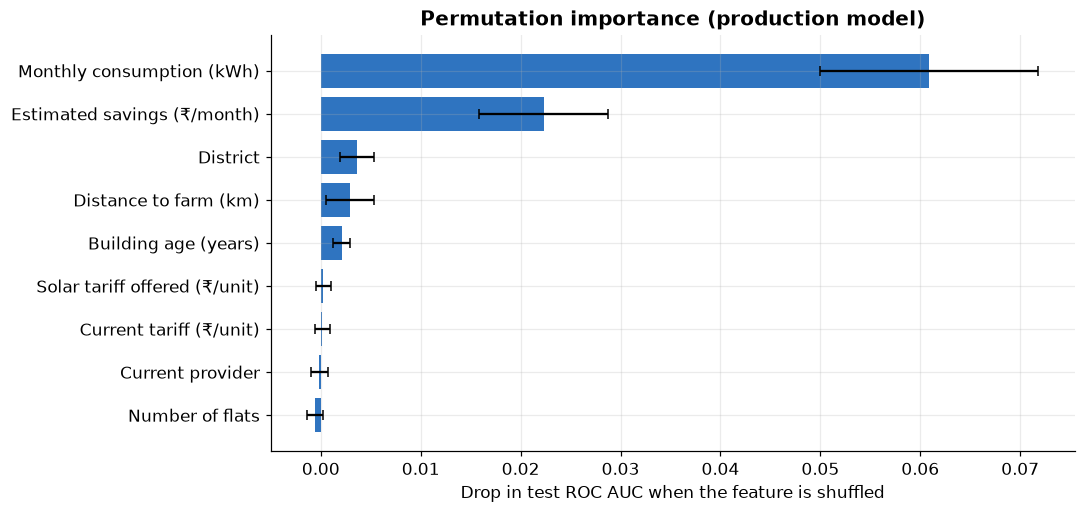

In [25]:
perm = permutation_importance(production, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=RANDOM_STATE)
imp = pd.DataFrame({"mean": perm.importances_mean, "std": perm.importances_std},
                   index=[LABELS[f] for f in FEATURES]).sort_values("mean")
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.barh(imp.index, imp["mean"], xerr=imp["std"], color=COLORS["blue"], capsize=3)
ax.set_xlabel("Drop in test ROC AUC when the feature is shuffled")
ax.set_title("Permutation importance (production model)")
plt.tight_layout()
plt.show()

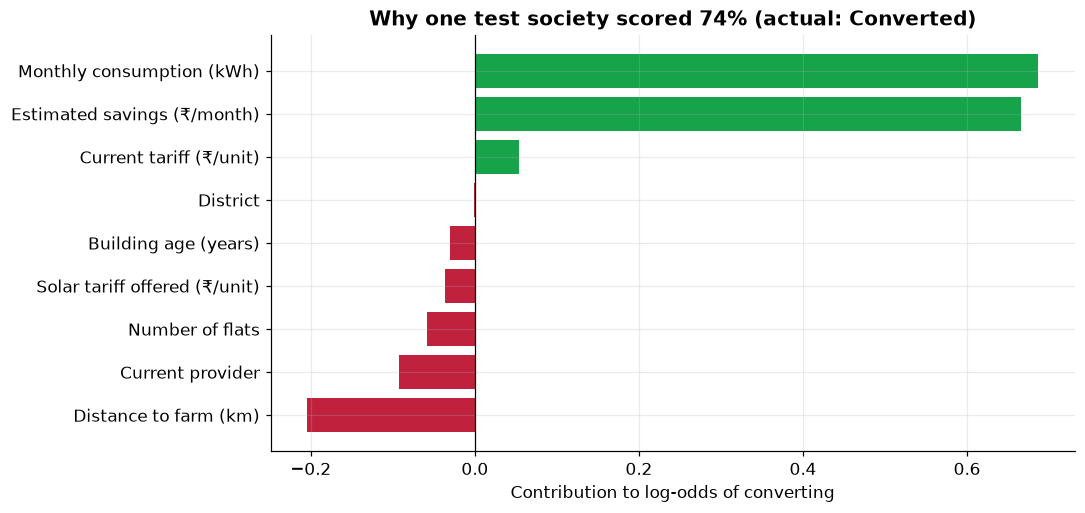

In [26]:
def explain(row):
    # Per-feature contribution to the log-odds: coefficient × transformed value, grouped by original feature.
    x = production.named_steps["preprocess"].transform(pd.DataFrame([row])[FEATURES])
    x = x.toarray()[0] if hasattr(x, "toarray") else np.asarray(x)[0]
    out = {}
    for name, value in zip(names, x * clf.coef_[0]):
        source = name.split("__", 1)[1]
        feature = next(f for f in FEATURES if source == f or source.startswith(f + "_"))
        out[LABELS[feature]] = out.get(LABELS[feature], 0) + value
    return pd.Series(out).sort_values()

example = X_test.iloc[0]
contrib = explain(example)
prob = production.predict_proba(pd.DataFrame([example]))[0, 1]
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.barh(contrib.index, contrib.values, color=[COLORS["green"] if v > 0 else COLORS["red"] for v in contrib.values])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Contribution to log-odds of converting")
ax.set_title(f"Why one test society scored {prob:.0%} (actual: {'Converted' if y_test.iloc[0] else 'Rejected'})")
plt.tight_layout()
plt.show()

## 15. Scoring the Pending societies (new leads)

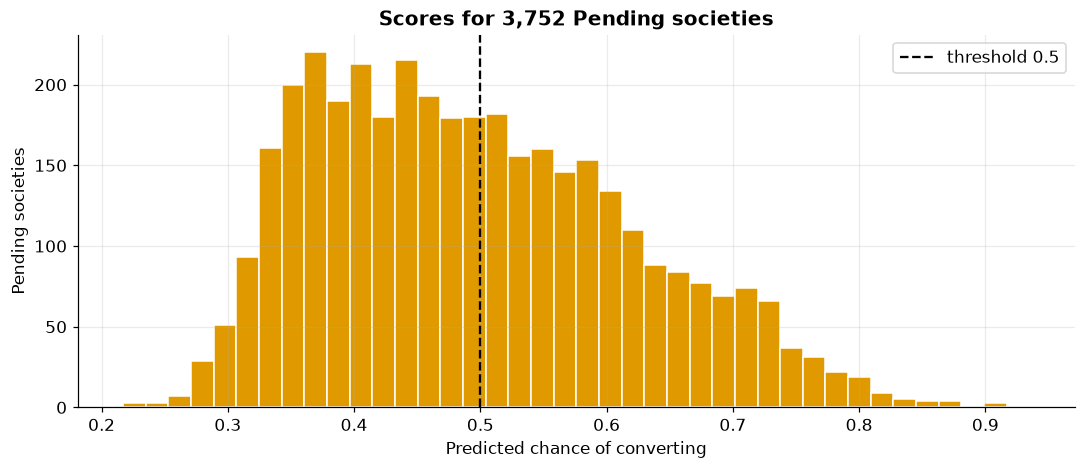

1,681 of 3,752 Pending societies are predicted to convert.


,society_name,city,num_flats,avg_monthly_consumption_kwh,estimated_monthly_savings_rs,prob
5744,Whispering Pines Residency 4,Mumbai,430,"197,138","₹408,076",93.5%
3984,Pearl Residency,Navi Mumbai,436,"163,957","₹411,532",91.1%
10653,Windsor Society,Navi Mumbai,428,"180,716","₹345,168",90.5%
3069,Emerald Enclave 1,Thane,444,"188,764","₹345,438",89.9%
2360,Sunrise Residency 2,Akola,449,"174,809","₹375,839",89.5%
3911,Sunshine Residency,Panvel,405,"154,116","₹388,372",87.7%
6329,Rosewood Heights 3,Thane,362,"145,614","₹308,702",86.7%
6564,Windsor CHS,Akola,442,"172,041","₹280,427",86.7%
6794,Orchid Gardens,Pune,449,"183,879","₹312,594",86.4%
12911,Rosewood Complex 7,Pune,423,"138,265","₹349,810",86.1%


In [27]:
pending = df[df["pitch_outcome"] == "Pending"].copy()
pending["prob"] = production.predict_proba(pending[FEATURES])[:, 1]

fig, ax = plt.subplots(figsize=(10, 4.4))
ax.hist(pending["prob"], bins=40, color=COLORS["amber"], edgecolor="white")
ax.axvline(0.5, ls="--", color="black", label="threshold 0.5")
ax.set_xlabel("Predicted chance of converting"); ax.set_ylabel("Pending societies")
ax.set_title(f"Scores for {len(pending):,} Pending societies"); ax.legend()
plt.tight_layout()
plt.show()
print(f"{(pending.prob >= 0.5).sum():,} of {len(pending):,} Pending societies are predicted to convert.")
pending.sort_values("prob", ascending=False)[["society_name", "city", "num_flats", "avg_monthly_consumption_kwh",
                                               "estimated_monthly_savings_rs", "prob"]].head(10) \
    .style.format({"prob": "{:.1%}", "avg_monthly_consumption_kwh": "{:,.0f}", "estimated_monthly_savings_rs": "₹{:,.0f}"})

## 16. From scores to a pitch plan

SolarLeads turns a probability into a decision for a farm (defaults match the dashboard: a **5 MW** farm,
**19%** capacity factor, **₹3.50/unit** generation cost, **25%** markup, **₹0.03/unit/km** transfer cost):

- **Savings** = (current tariff − our solar offer) × monthly consumption
- **Expected value** = chance to convert × monthly savings
- **Allocation**: choose the set of societies with the highest total expected value that fits the farm's monthly output
- **Quadrants**: chance ≥ 50% means low risk; savings above the median means high reward

### Allocation as an integer linear program (0/1 knapsack)

For each eligible society *i*, the decision is $x_i \in \{0, 1\}$ (pitch it or not):

$$\max \sum_i p_i \, s_i \, x_i \quad \text{subject to} \quad \sum_i \text{kWh}_i \, x_i \le \text{farm output per month}, \quad x_i \in \{0,1\}$$

where $p_i$ is the model's probability and $s_i$ the monthly savings. This is the 0/1 knapsack problem. We solve it
exactly with `scipy.optimize.milp` (the HiGHS solver). The simple alternative, a **greedy fill** (take the highest
expected value first and stop when the next society does not fit), is shown for comparison.

Greedy fill       3 societies · farm used  78.3% · expected value ₹  32.3 lakh a month
ILP (knapsack)    6 societies · farm used  99.9% · expected value ₹  42.1 lakh a month


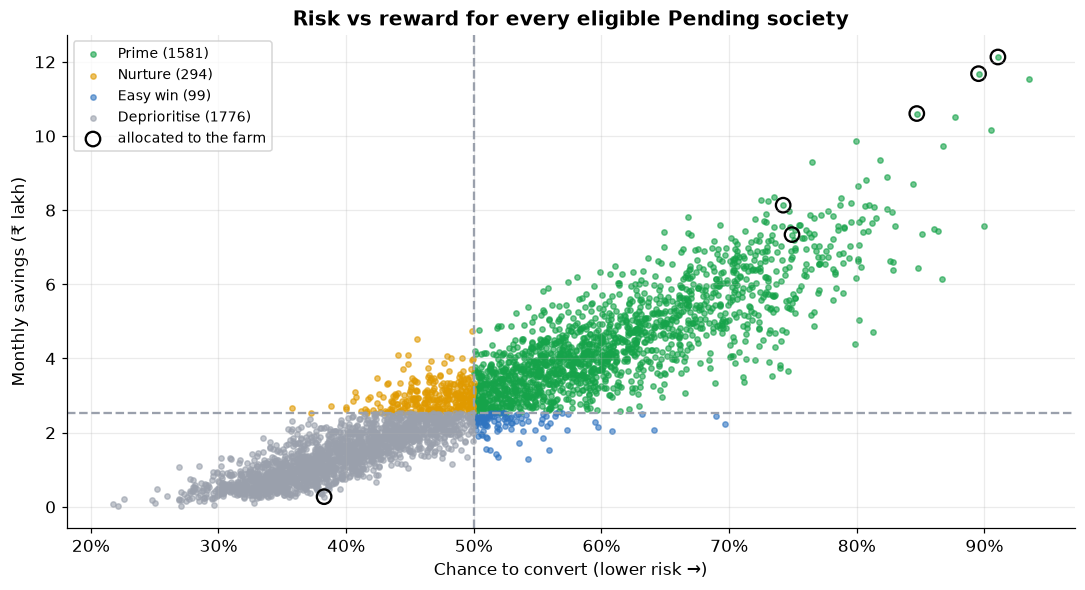

In [28]:
from scipy.optimize import Bounds, LinearConstraint, milp


def knapsack(values, weights, capacity):
    # 0/1 knapsack by ILP: maximise values·x subject to weights·x <= capacity, x binary.
    values, weights = np.asarray(values, float), np.asarray(weights, float)
    res = milp(-values, constraints=LinearConstraint(weights[None, :], 0, capacity),
               integrality=np.ones(len(values)), bounds=Bounds(0, 1))
    return res.x > 0.5


def greedy(weights, capacity):
    # Assumes rows are sorted by expected value, best first.
    return np.cumsum(weights) <= capacity


CAPACITY_MW, CUF, GEN_COST, MARKUP, TRANSFER = 5, 0.19, 3.5, 0.25, 0.03
capacity_kwh = CAPACITY_MW * 1000 * 24 * 30 * CUF
plan = pending.copy()
plan["offer"] = (GEN_COST + TRANSFER * plan["distance_to_solar_farm_km"]) * (1 + MARKUP)
plan["savings"] = (plan["current_tariff_rs_per_unit"] - plan["offer"]) * plan["avg_monthly_consumption_kwh"]
plan = plan[plan["savings"] > 0]
plan["expected_value"] = plan["prob"] * plan["savings"]
plan = plan.sort_values("expected_value", ascending=False)
plan["greedy"] = greedy(plan["avg_monthly_consumption_kwh"], capacity_kwh)
plan["allocated"] = knapsack(plan["expected_value"], plan["avg_monthly_consumption_kwh"], capacity_kwh)
for name, col in [("Greedy fill", "greedy"), ("ILP (knapsack)", "allocated")]:
    sel = plan[plan[col]]
    print(f"{name:15s} {len(sel):3d} societies · farm used {sel.avg_monthly_consumption_kwh.sum() / capacity_kwh:6.1%} · "
          f"expected value ₹{sel.expected_value.sum() / 1e5:6.1f} lakh a month")

median_saving = plan["savings"].median()
fig, ax = plt.subplots(figsize=(10, 5.5))
quad = np.select([(plan.prob >= .5) & (plan.savings >= median_saving), (plan.prob < .5) & (plan.savings >= median_saving),
                  (plan.prob >= .5)], ["Prime", "Nurture", "Easy win"], "Deprioritise")
for q, color in [("Prime", COLORS["green"]), ("Nurture", COLORS["amber"]), ("Easy win", COLORS["blue"]), ("Deprioritise", COLORS["grey"])]:
    m = quad == q
    ax.scatter(plan.prob[m], plan.savings[m] / 1e5, s=12, alpha=0.6, color=color, label=f"{q} ({m.sum()})")
ax.scatter(plan.prob[plan.allocated], plan.savings[plan.allocated] / 1e5, s=90, facecolors="none", edgecolors="black",
           lw=1.5, label="allocated to the farm")
ax.axvline(0.5, ls="--", color=COLORS["grey"]); ax.axhline(median_saving / 1e5, ls="--", color=COLORS["grey"])
ax.set_xlabel("Chance to convert (lower risk →)"); ax.set_ylabel("Monthly savings (₹ lakh)")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_title("Risk vs reward for every eligible Pending society"); ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

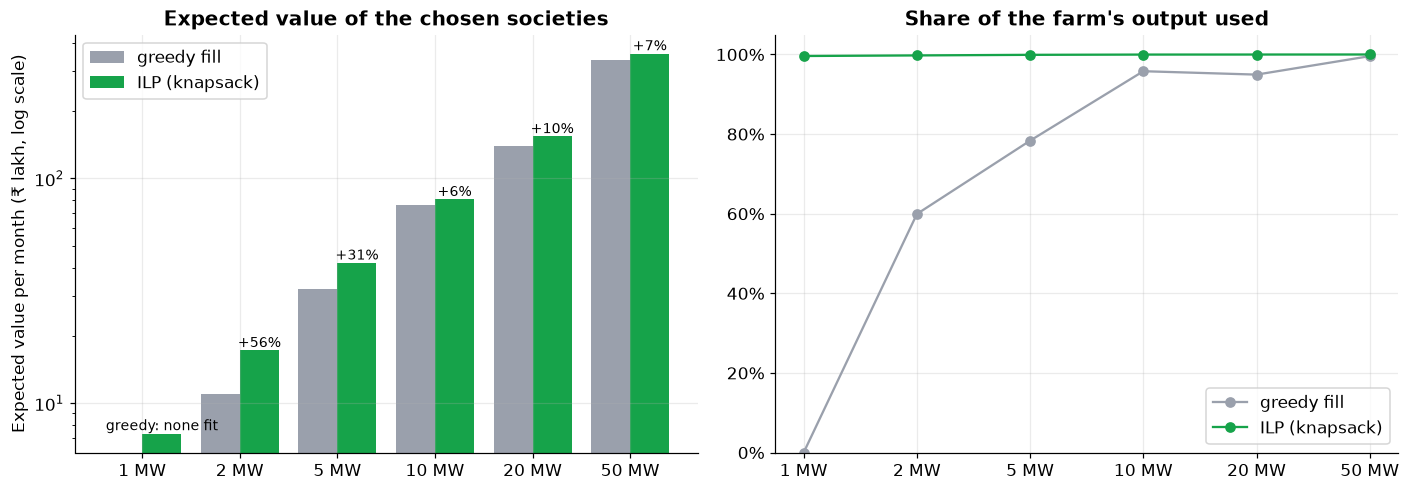

,greedy EV (₹ lakh),ILP EV (₹ lakh),greedy farm used,ILP farm used,ILP gain
farm (MW),,,,,
1,0.0,7.3,0.0%,99.6%,greedy picks none
2,11.0,17.2,59.9%,99.8%,+55.6%
5,32.3,42.1,78.3%,99.9%,+30.5%
10,76.0,80.8,95.8%,100.0%,+6.3%
20,139.5,153.9,94.9%,100.0%,+10.3%
50,337.1,359.6,99.6%,100.0%,+6.7%


In [29]:
# Greedy vs ILP across farm sizes. Greedy stops at the first society that does not fit, so large
# societies can block the list and leave capacity unused; the ILP finds the best combination.
rows = []
for mw in [1, 2, 5, 10, 20, 50]:
    cap = mw * 1000 * 24 * 30 * CUF
    g = greedy(plan["avg_monthly_consumption_kwh"], cap)
    x = knapsack(plan["expected_value"], plan["avg_monthly_consumption_kwh"], cap)
    rows.append({"farm (MW)": mw,
                 "greedy EV (₹ lakh)": plan.expected_value[g].sum() / 1e5, "ILP EV (₹ lakh)": plan.expected_value[x].sum() / 1e5,
                 "greedy farm used": plan.avg_monthly_consumption_kwh[g].sum() / cap,
                 "ILP farm used": plan.avg_monthly_consumption_kwh[x].sum() / cap})
alloc = pd.DataFrame(rows).set_index("farm (MW)")
# At 1 MW the single best society is larger than the farm, so the greedy fill picks nothing at all.
alloc["ILP gain"] = alloc["ILP EV (₹ lakh)"] / alloc["greedy EV (₹ lakh)"].replace(0, np.nan) - 1

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
pos = np.arange(len(alloc))
axes[0].bar(pos - 0.2, alloc["greedy EV (₹ lakh)"], 0.4, color=COLORS["grey"], label="greedy fill")
axes[0].bar(pos + 0.2, alloc["ILP EV (₹ lakh)"], 0.4, color=COLORS["green"], label="ILP (knapsack)")
for i, gain in enumerate(alloc["ILP gain"]):
    label = "greedy: none fit" if not np.isfinite(gain) else f"+{gain:.0%}"
    axes[0].annotate(label, (i + 0.2, alloc["ILP EV (₹ lakh)"].iloc[i]), ha="center", va="bottom", fontsize=9)
axes[0].set_xticks(pos, [f"{m} MW" for m in alloc.index]); axes[0].set_yscale("log")
axes[0].set_ylabel("Expected value per month (₹ lakh, log scale)"); axes[0].set_title("Expected value of the chosen societies")
axes[0].legend()
axes[1].plot(pos, alloc["greedy farm used"], "o-", color=COLORS["grey"], label="greedy fill")
axes[1].plot(pos, alloc["ILP farm used"], "o-", color=COLORS["green"], label="ILP (knapsack)")
axes[1].set_xticks(pos, [f"{m} MW" for m in alloc.index]); axes[1].set_ylim(0, 1.05)
axes[1].yaxis.set_major_formatter(PercentFormatter(1)); axes[1].set_title("Share of the farm's output used")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()
alloc.style.format({"greedy EV (₹ lakh)": "{:.1f}", "ILP EV (₹ lakh)": "{:.1f}", "greedy farm used": "{:.1%}",
                    "ILP farm used": "{:.1%}", "ILP gain": "+{:.1%}"}, na_rep="greedy picks none")

In [30]:
# Groups to pitch together: societies in the same city, chosen by the same ILP to fill the farm.
groups = []
for city, g in plan.groupby("city"):
    members = g[knapsack(g["expected_value"], g["avg_monthly_consumption_kwh"], capacity_kwh)]
    if len(members):
        groups.append({"area": city, "societies": len(members), "avg chance": members.prob.mean(),
                       "expected sign-ups": members.prob.sum(), "monthly savings (₹ lakh)": members.savings.sum() / 1e5,
                       "expected value (₹ lakh)": members.expected_value.sum() / 1e5,
                       "farm filled": members.avg_monthly_consumption_kwh.sum() / capacity_kwh})
groups = pd.DataFrame(groups).sort_values("expected value (₹ lakh)", ascending=False).head(8).reset_index(drop=True)
groups.index += 1
groups.style.format({"avg chance": "{:.1%}", "expected sign-ups": "{:.1f}", "monthly savings (₹ lakh)": "{:.1f}",
                     "expected value (₹ lakh)": "{:.1f}", "farm filled": "{:.0%}"})

,area,societies,avg chance,expected sign-ups,monthly savings (₹ lakh),expected value (₹ lakh),farm filled
1,Navi Mumbai,5,81.6%,4.1,45.7,38.1,100%
2,Mumbai,5,81.6%,4.1,45.2,37.6,100%
3,Akola,7,69.4%,4.9,48.0,36.0,100%
4,Thane,7,70.6%,4.9,45.8,35.2,100%
5,Panvel,7,68.6%,4.8,47.3,34.8,100%
6,Nashik,6,72.0%,4.3,43.3,34.4,100%
7,Aurangabad,7,70.3%,4.9,46.8,33.2,100%
8,Latur,6,77.3%,4.6,42.9,33.2,100%


## 17. Monte Carlo simulation: the risk inside a group

"Expect 4.0 of 5 to sign" is an average. A sales team also needs the spread: how bad can it get? Each society
signs (1) or not (0) with its own probability $p_i$, so the number of sign-ups is a sum of independent Bernoulli
trials. We pitch the best group **10,000 times** in simulation and count the results each time.

Two numbers have exact formulas, so they check the simulation:
- expected sign-ups $= \sum_i p_i$
- chance that at least one signs $= 1 - \prod_i (1 - p_i)$

The simulation also gives what the formulas do not: the range that holds 9 times out of 10, and how often the farm
ends up at least half full.

Group: 5 societies in Navi Mumbai
Expected sign-ups  formula 4.079 | simulation 4.086
P(at least one)    formula 0.9999 | simulation 1.0000
9 times out of 10: 3–5 of 5 sign · farm at least half full in 97% of rounds


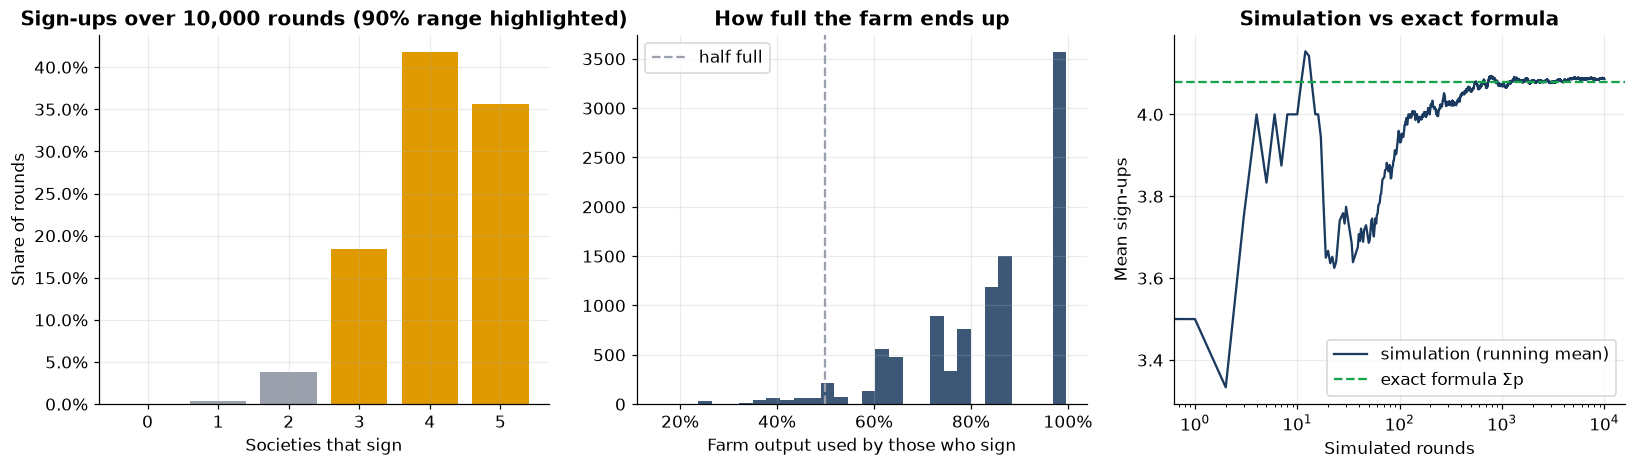

In [31]:
RUNS = 10_000
best_city = groups.iloc[0]["area"]
g = plan[plan.city == best_city]
group = g[knapsack(g["expected_value"], g["avg_monthly_consumption_kwh"], capacity_kwh)]
p, kwh = group["prob"].to_numpy(), group["avg_monthly_consumption_kwh"].to_numpy()

rng = np.random.default_rng(0)
signed = rng.random((RUNS, len(p))) < p          # one row per simulated round, one column per society
signups = signed.sum(axis=1)
fill = signed @ kwh / capacity_kwh
low, high = np.quantile(signups, [0.05, 0.95], method="inverted_cdf")

print(f"Group: {len(p)} societies in {best_city}")
print(f"Expected sign-ups  formula {p.sum():.3f} | simulation {signups.mean():.3f}")
print(f"P(at least one)    formula {1 - np.prod(1 - p):.4f} | simulation {(signups > 0).mean():.4f}")
print(f"9 times out of 10: {int(low)}–{int(high)} of {len(p)} sign · farm at least half full in {(fill >= 0.5).mean():.0%} of rounds")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
counts = np.bincount(signups, minlength=len(p) + 1) / RUNS
axes[0].bar(range(len(counts)), counts,
            color=[COLORS["amber"] if low <= k <= high else COLORS["grey"] for k in range(len(counts))])
axes[0].set_xlabel("Societies that sign"); axes[0].set_ylabel("Share of rounds")
axes[0].yaxis.set_major_formatter(PercentFormatter(1)); axes[0].set_title("Sign-ups over 10,000 rounds (90% range highlighted)")
axes[1].hist(fill, bins=30, color=COLORS["navy"], alpha=0.85)
axes[1].axvline(0.5, ls="--", color=COLORS["grey"], label="half full")
axes[1].xaxis.set_major_formatter(PercentFormatter(1)); axes[1].set_xlabel("Farm output used by those who sign")
axes[1].set_title("How full the farm ends up"); axes[1].legend()
running = np.cumsum(signups) / np.arange(1, RUNS + 1)
axes[2].plot(running, color=COLORS["navy"], lw=1.5, label="simulation (running mean)")
axes[2].axhline(p.sum(), ls="--", color=COLORS["green"], label="exact formula Σp")
axes[2].set_xscale("log"); axes[2].set_xlabel("Simulated rounds"); axes[2].set_ylabel("Mean sign-ups")
axes[2].set_title("Simulation vs exact formula"); axes[2].legend()
plt.tight_layout()
plt.show()

## 18. Live-stream replay

The dashboard streams held-out societies through the model one at a time and shows accuracy settling as
results accumulate. This replays the same thing offline.

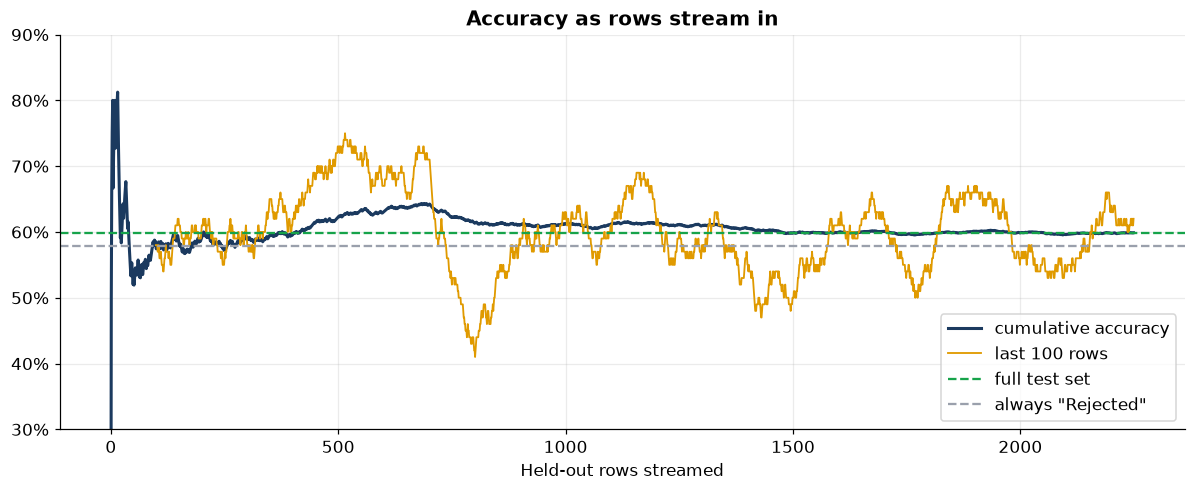

In [32]:
order = np.random.default_rng(7).permutation(len(X_test))
correct = ((p_prod[order] >= 0.5).astype(int) == y_test.to_numpy()[order]).astype(float)
cumulative = np.cumsum(correct) / np.arange(1, len(correct) + 1)
rolling = pd.Series(correct).rolling(100).mean()

fig, ax = plt.subplots(figsize=(11, 4.6))
ax.plot(cumulative, color=COLORS["navy"], lw=2, label="cumulative accuracy")
ax.plot(rolling, color=COLORS["amber"], lw=1.2, label="last 100 rows")
ax.axhline(accuracy_score(y_test, p_prod >= 0.5), ls="--", color=COLORS["green"], label="full test set")
ax.axhline(baseline_acc, ls="--", color=COLORS["grey"], label='always "Rejected"')
ax.set_ylim(0.3, 0.9); ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("Held-out rows streamed"); ax.set_title("Accuracy as rows stream in")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 19. Conclusions

| | Result |
|---|---|
| Production model | Class-balanced logistic regression, about 60% accuracy and 0.61 ROC AUC on the held-out test set |
| Baseline | Always predicting "Rejected" scores about 58% |
| Other models | Gradient descent matches the production solver; the neural network and gradient boosting do not beat it |
| Strongest signals | Monthly consumption, estimated savings and number of flats |
| Uses | Ranks 3,752 Pending societies, allocates a farm's capacity and proposes groups to pitch together |
| Allocation | Integer linear programming (0/1 knapsack) beats the greedy fill and uses almost all of the farm's output |
| Risk | Monte Carlo simulation gives the range of sign-ups for each group; it agrees with the exact formulas |

**Why logistic regression in production:** it matches or beats the more complex models here, trains in milliseconds,
and every prediction can be explained feature by feature, which the dashboard and client portal show to users.

**Limitations (honest):**
- The dataset is synthetic, and most features carry little signal, so accuracy is modest. The learning curve shows more rows
  of the same features will not fix this; richer real-world features would.
- Map positions in the app are city-level, not exact addresses.
- Savings use a simple tariff model; real offers would include fixed charges and contract terms.

## 20. Save the trained model and metrics

In [33]:
import json

import joblib

joblib.dump(production, "solarleads_logreg.joblib")
summary = {
    "test_metrics": comparison.round(4).to_dict(orient="index"),
    "cv_roc_auc": {k: {"mean": float(v.mean()), "std": float(v.std())} for k, v in cv_scores.items()},
    "train_rows": len(X_train_full), "test_rows": len(X_test), "pending_scored": len(pending),
}
with open("solarleads_metrics.json", "w") as f:
    json.dump(summary, f, indent=2)
print("Saved solarleads_logreg.joblib and solarleads_metrics.json")

# On Colab, uncomment to download them:
# from google.colab import files; files.download("solarleads_logreg.joblib"); files.download("solarleads_metrics.json")

Saved solarleads_logreg.joblib and solarleads_metrics.json
